# Franklin Database Analysis

Import Libraries

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Frequency Analysis

In [10]:
df = pd.read_csv('new_normalizations/category_summary2.csv')

pivot = df.pivot_table(index="category", columns="city", values="count", fill_value=0, aggfunc="sum")
pivot["total"] = pivot.sum(axis=1)
pivot = pivot.sort_values("total", ascending=False)
print(pivot)

city                             Franklin  Knoxville  Memphis  Murfreesboro  \
category                                                                      
Case Numbers / Names                  107       3306     1857         29166   
Malformed / Unintelligible              7      31047      203            72   
General Investigation                2689      12402    11805          3002   
REDACTED                             1309       2758    10840          2551   
BOLO / Suspect Vehicle                339       7385     2081          4382   
Stolen Vehicle / MVT                  655       1575     5926          1426   
Warrant / Wanted Person               121       5930     1813           941   
Violent / Sexual Crime                237       2131     2081          2643   
Routine / Administrative / Test       482        824      688           823   
Traffic / Crash                        39        481      140           630   
Drug Investigation                      0       2451

Just from observation, Franklin appears to hold the 2nd least amount of data when compared to the others. Its highest crime category was general investigations, which appears to be common across the other cities. Its 2nd highest crime category, exculding malformed values, is stolen vehicles, which is popular among the rest of the datasets but its popularity varies.

It is worth noting that Franklin had 0 Drug investigations in the entire ~6,000 row dataset. I thought this would be significant, but due to the discrepancy in the amount of data compared to the other PDs, making a conclusion off it would be misleading.

Graph for Franklin:

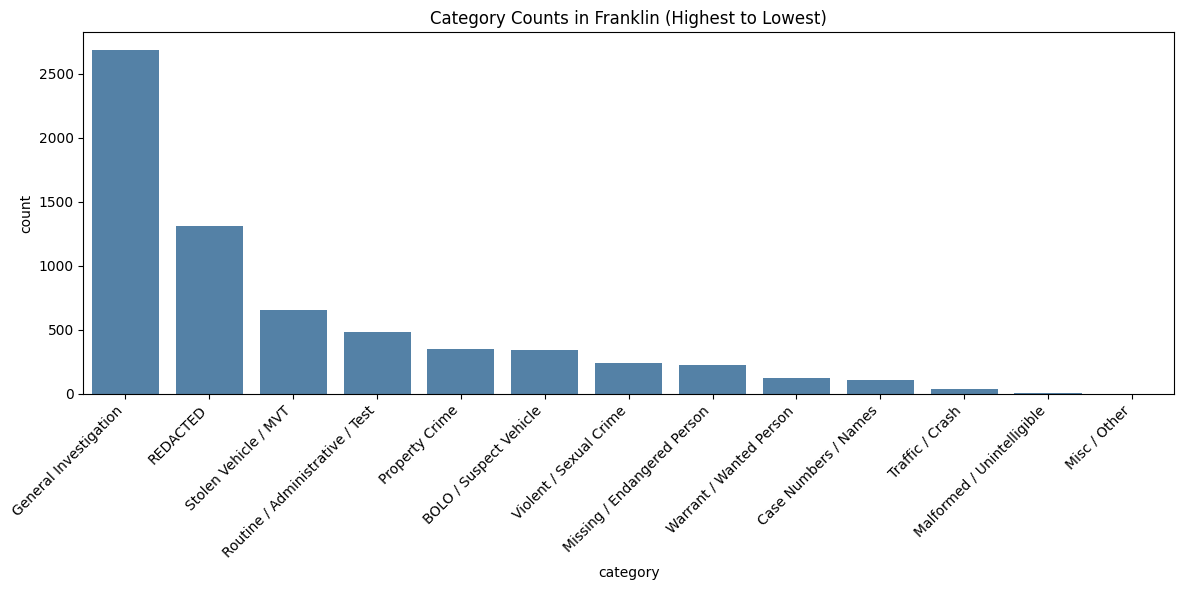

In [17]:
graph_df = df[df["city"] == "Franklin"]
graph_df = graph_df.sort_values("count", ascending=False)

# Create bar graph
plt.figure(figsize=(12, 6))

sns.barplot(
    data=graph_df,
    x="category",
    y="count",
    color="steelblue"
)

plt.title(f"Category Counts in Franklin (Highest to Lowest)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## User Search Analysis
Seeing what kind of crimes each officer is searching for.

In [11]:
frank_df = pd.read_csv("new_normalizations/Franklin_categorized.csv")

name_lookups = frank_df.groupby(["name", "reason_category"], dropna=False).size().reset_index(name="Count")

print(name_lookups.to_string())

      name                  reason_category  Count
0   A. Ale                         REDACTED      1
1   A. Ale  Routine / Administrative / Test      2
2       B.                   Property Crime      1
3       B.  Routine / Administrative / Test      2
4   C. Buc            General Investigation      2
5   C. Buc      Missing / Endangered Person      2
6   C. Buc  Routine / Administrative / Test      8
7   C. Doy            General Investigation    146
8   C. Doy                   Property Crime      2
9   C. Doy                         REDACTED     11
10  C. Doy  Routine / Administrative / Test    136
11  C. Doy                  Traffic / Crash      2
12  C. Doy           Violent / Sexual Crime      2
13  C. Jon  Routine / Administrative / Test     10
14  C. Tra           BOLO / Suspect Vehicle    145
15  C. Tra             Case Numbers / Names     19
16  C. Tra            General Investigation      3
17  C. Tra       Malformed / Unintelligible      1
18  C. Tra      Missing / Endan

In [12]:
frank_df["name"].value_counts(dropna=False)

name
NaN       4254
C. rig     799
C. Tra     739
C. Doy     299
J. Ake      93
W. Ora      87
T. Nor      82
J.          58
S. Bil      32
M. Tho      31
J. Mor      16
C. Buc      12
C. Jon      10
K. Bri      10
J. Sha       8
I. Car       6
J. And       4
k. Spr       4
S. Sch       4
J. Car       3
A. Ale       3
B.           3
S. Gre       2
Name: count, dtype: int64

Just from looking at the counts, we can see that C. rig, Tra and Doy have all made the most public calls to the Flock databse. Unfortunately, most of their calls were for routine investigations, so it hard to determine if one was specifically looking for a specific department. The only thing worth noting is that Ake works alot in property crime and endangered persons. 

Another thing worth noting is that given the large amount of redacted users, there are not a lot of redacted reasons for what they are searching for. Even with 4,254 redacted calls, there are only 54 related redacted reasons given. It is confusing to see for what reason that the names are redacted for when so many reasons are kept recorded. I was originally thinking that a high redacted reasons rate could lead to abuse but this kinda proves the opposite. Of course they could also fake the reasons tab altogether so it is not all that important.

# Seasonal Crime Analysis

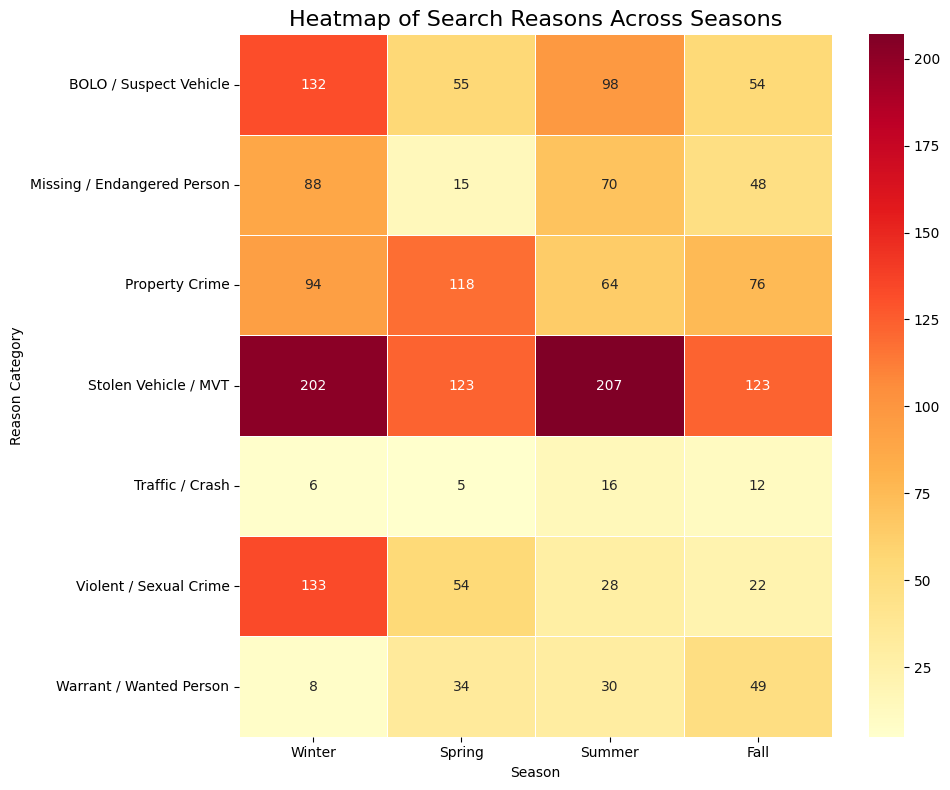

In [15]:
frank_df["search_time_utc"] = pd.to_datetime(frank_df["search_time_utc"])

def get_season(date):
    month = date.month

    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"

frank_df["Season"] = frank_df["search_time_utc"].apply(get_season)

seasons = frank_df.groupby(["Season", "reason_category"], dropna=False).size().reset_index(name="Count")

season_order = ["Winter", "Spring", "Summer", "Fall"]

seasons["Season"] = pd.Categorical(
    seasons["Season"],
    categories=season_order,
    ordered=True
)

seasons = seasons.sort_values("Season")

excluded_categories = ["Case Numbers / Names", "REDACTED", "Malformed / Unintelligible", "Misc / Other", "General Investigation", "Routine / Administrative / Test"]

seasons = seasons[
    ~seasons["reason_category"].isin(excluded_categories)
]

heatmap_data = seasons.pivot(
    index="reason_category",
    columns="Season",
    values="Count"
).fillna(0)

heatmap_data = heatmap_data[season_order]

plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Heatmap of Search Reasons Across Seasons", fontsize=16)
plt.xlabel("Season")
plt.ylabel("Reason Category")

plt.tight_layout()
plt.show()

There is some interesting data here seeing that most crimes seem to peak in the winter months, with a lot hotter heat map spots appearing in that region. This kind of contradicts most studies which state that crime rates usually lower in the winter months. However, some studies do state that temperature fluctuations can cause increases in crime, which is exactly what happens in the winter and summer months for stolen vehicles.

## Manual Reason Review

Of course, the normalizations can help for looking at specific crime statistics, but is there anything interesting within the reasons themselves? Upon Further review, I found one instance in which a officer named K. Bri had performed a search with the stated reason being "Assist IRS". This is very notable as it relates to the flock systems being used for reasons not related to immediate criminal activity, but even for other governmental bodies such as the IRS. I tried to find if there was any policy that rejected against this but it seems like this is allowed for the departments. I did see that the IRS were not allowed to directly use these sytems for basic investigations, so the fact that it only appears once probalby means there was no ill intentions.